# Tesseract OCR Baseline for Water Meter Recognition (Kaggle)
Fine-tuning Tesseract 5 LSTM bằng `tesstrain` và tiền xử lý ảnh theo bài báo arXiv:2004.08079 (Zacharias et al.).
Đồng bộ cấu hình huấn luyện (200 Epochs, Learning Rate 1e-3, Levenshtein Metrics) để đối chiếu trực tiếp với CRNN Baseline.

## 1. Cài đặt thư viện hệ thống trên Kaggle

In [1]:
# Kiểm tra kết nối Internet trên Kaggle
import urllib.request

try:
    urllib.request.urlopen("https://www.google.com", timeout=3)
    print("Internet: ĐÃ BẬT (ONLINE)")
except Exception:
    print("CẢNH BÁO: INTERNET ĐANG TẮT! Vào menu Settings -> Bật 'Internet on' để tải thư viện.")

# Cài đặt nhanh Tesseract & thư viện cần thiết
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr libtesseract-dev libleptonica-dev
!pip install -q pytesseract Levenshtein

Internet: ĐÃ BẬT (ONLINE)
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../libattr1_1%3a2.5.2-1ubuntu0.1_amd64.deb ...
Unpacking libattr1:amd64 (1:2.5.2-1ubuntu0.1) over (1:2.5.2-1build1) ...
Setting up libattr1:amd64 (1:2.5.2-1ubuntu0.1) ...
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../libgmp10_2%3a6.3.0+dfsg-2ubuntu6.1_amd64.deb ...
Unpacking libgmp10:amd64 (2:6.3.0+dfsg-2ubuntu6.1) over (2:6.3.0+dfsg-2ubuntu6) ...
Setting up libgmp10:amd64 (2:6.3.0+dfsg-2ubuntu6.1) ...
(Reading database ... 

## 2. Chuẩn bị tesstrain và base model eng.traineddata

In [2]:
from pathlib import Path

TESSTRAIN_DIR = Path('/kaggle/working/tesstrain')
if not TESSTRAIN_DIR.exists():
    !git clone https://github.com/tesseract-ocr/tesstrain.git {TESSTRAIN_DIR}

TESSDATA_DIR = TESSTRAIN_DIR / 'usr' / 'share' / 'tessdata'
TESSDATA_DIR.mkdir(parents=True, exist_ok=True)

ENG_MODEL = TESSDATA_DIR / 'eng.traineddata'
if not ENG_MODEL.exists():
    !wget -q -O {ENG_MODEL} https://github.com/tesseract-ocr/tessdata_best/raw/main/eng.traineddata

Cloning into '/kaggle/working/tesstrain'...
remote: Enumerating objects: 1119, done.
remote: Counting objects: 100% (472/472), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 1119 (delta 440), reused 410 (delta 410), pack-reused 647 (from 2)
Receiving objects: 100% (1119/1119), 13.52 MiB | 41.45 MiB/s, done.
Resolving deltas: 100% (660/660), done.


## 3. Tiền xử lý ảnh theo arXiv:2004.08079 (Section 2.2 & Fig. 4)

In [3]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import pytesseract
import shutil
import re
import random

class WaterMeterPaperPreprocessor:
    def __init__(self, padding=15):
        self.padding = padding

    @staticmethod
    def calculate_rms_brightness(img_gray):
        return np.sqrt(np.mean(img_gray.astype(np.float64) ** 2))

    @staticmethod
    def gamma_correction_lut(img, gamma=1.0):
        inv_gamma = 1.0 / max(gamma, 1e-4)
        lut = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype(np.uint8)
        return cv2.LUT(img, lut)

    @staticmethod
    def correct_skew(gray):
        """Skew correction bằng Canny Edge + HoughLinesP (Fig. 4 - Step 2)"""
        h, w = gray.shape[:2]
        edges = cv2.Canny(gray, 50, 150, apertureSize=3)
        min_line_len = max(int(w * 0.2), 15)
        lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=30, minLineLength=min_line_len, maxLineGap=10)
        if lines is not None and len(lines) > 0:
            angles = []
            for line in lines:
                x1, y1, x2, y2 = line[0]
                if x2 - x1 != 0:
                    ang = np.degrees(np.arctan2(y2 - y1, x2 - x1))
                    if abs(ang) < 45:
                        angles.append(ang)
            if angles:
                median_angle = float(np.median(angles))
                if abs(median_angle) > 0.5:
                    center = (w // 2, h // 2)
                    M = cv2.getRotationMatrix2D(center, median_angle, 1.0)
                    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
        return gray

    def preprocess(self, img_bgr_or_gray, debug=False):
        # 1. Image (Grayscale + RMS Gamma Correction)
        gray = cv2.cvtColor(img_bgr_or_gray, cv2.COLOR_BGR2GRAY) if len(img_bgr_or_gray.shape) == 3 else img_bgr_or_gray.copy()
        rms = self.calculate_rms_brightness(gray)
        gamma = 1.5 if rms < 70 else (0.7 if rms > 180 else 1.0)
        corrected = self.gamma_correction_lut(gray, gamma)

        # 2. Skew Correction (Fig. 4 - Step 2)
        deskewed = self.correct_skew(corrected)

        # 3. Gaussian Blurring & Blackhat Operator (Fig. 4 - Step 3)
        blurred = cv2.GaussianBlur(deskewed, (3, 3), 0)
        rect_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
        blackhat = cv2.morphologyEx(blurred, cv2.MORPH_BLACKHAT, rect_kernel)

        # 4. Scharr Gradient Operator (Fig. 4 - Step 4)
        grad_x = cv2.Scharr(blackhat, cv2.CV_32F, 1, 0)
        grad_y = cv2.Scharr(blackhat, cv2.CV_32F, 0, 1)
        grad_mag = cv2.magnitude(grad_x, grad_y)
        grad_mag = cv2.normalize(grad_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

        # 5. Closing Operation (Fig. 4 - Step 5)
        close_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
        closed = cv2.morphologyEx(grad_mag, cv2.MORPH_CLOSE, close_kernel)

        # 6. Otsu Thresholding (Fig. 4 - Step 6)
        _, thresh = cv2.threshold(closed, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

        # 7. ROI: Giữ nguyên độ phân giải chuẩn (H=60, ký tự ~45px) và thêm viền đệm trắng cho Tesseract
        final_img = cv2.copyMakeBorder(
            deskewed, 
            self.padding, self.padding, self.padding, self.padding, 
            cv2.BORDER_CONSTANT, value=255
        )

        if debug:
            return {
                '1. Image': gray,
                '2. Skew Correction': deskewed,
                '3. Blackhat Operator': blackhat,
                '4. Scharr Operator': grad_mag,
                '5. Closing Operation': closed,
                '6. Otsu Thresholding': thresh,
                '7. ROI': final_img
            }
        return final_img

preprocessor = WaterMeterPaperPreprocessor()

## 4. Trực quan hóa các bước tiền xử lý ảnh (Fig. 4)

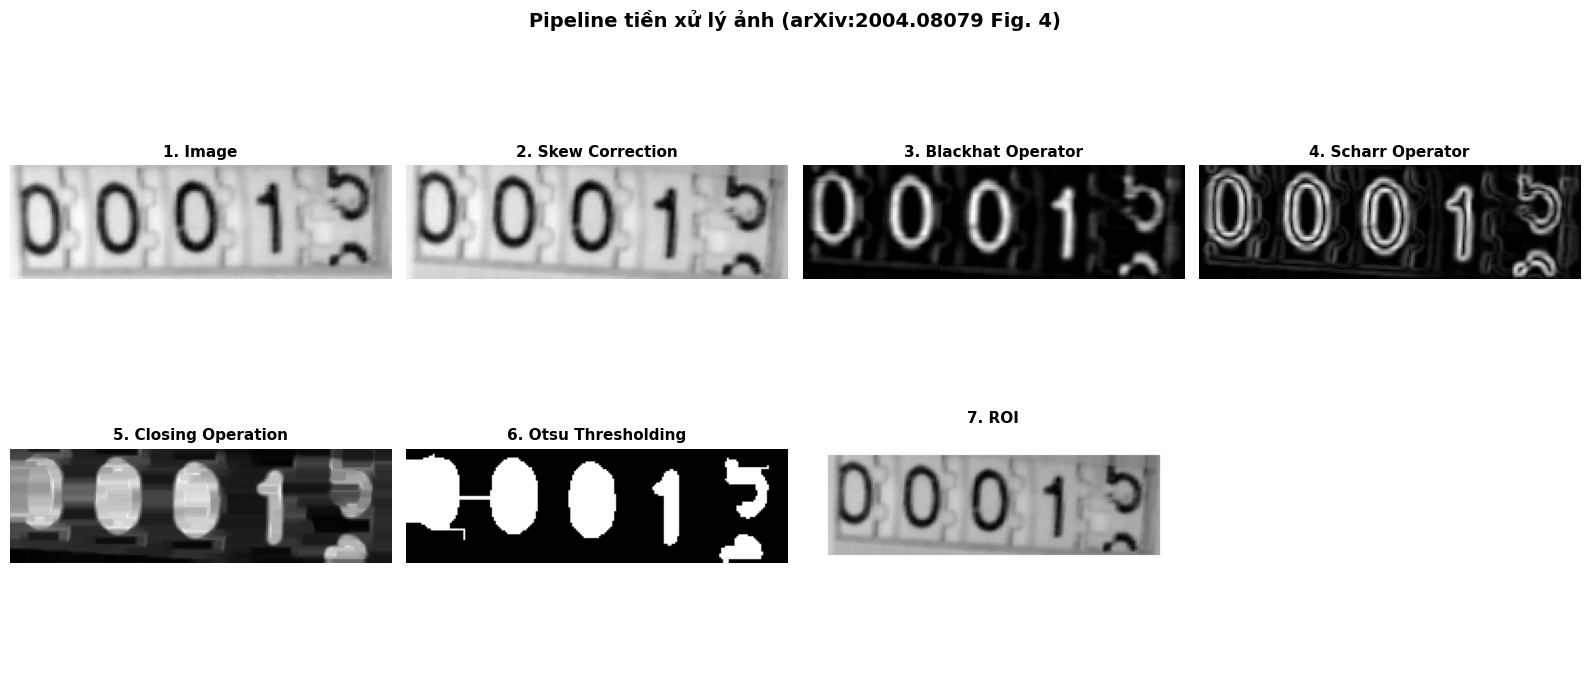

In [4]:
ROOT = Path('/kaggle/input/datasets/lmgiathnh/recognition-5-6-digits')
DATA_DIR = ROOT / 'recognition_merge_2'
if not DATA_DIR.exists():
    DATA_DIR = Path('/kaggle/input/datasets/lmgiathnh/recognition-5-6-digits/recognition_merge_2')

sample_img_path = DATA_DIR / 'train' / 'images' / 'train_0_5d.jpg'
sample_bgr = cv2.imread(str(sample_img_path))
steps = preprocessor.preprocess(sample_bgr, debug=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for idx, (title, img_step) in enumerate(steps.items()):
    axes[idx].imshow(img_step, cmap='gray')
    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    axes[idx].axis('off')
axes[7].axis('off')
plt.suptitle('Pipeline tiền xử lý ảnh (arXiv:2004.08079 Fig. 4)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Chuẩn bị dữ liệu Ground Truth cho tesstrain

In [5]:
GT_DIR = TESSTRAIN_DIR / 'data' / 'watermeter-ground-truth'
if GT_DIR.exists():
    shutil.rmtree(GT_DIR)
GT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATA_DIR / 'train' / 'train_labels.csv'
TRAIN_IMAGES = DATA_DIR / 'train' / 'images'

train_df = pd.read_csv(TRAIN_CSV, dtype={'label': str})
print(f'Training samples: {len(train_df)}')

for idx, row in tqdm(train_df.iterrows(), total=len(train_df), desc='Generating Ground Truth'):
    img_name = row['filename']
    label = str(row['label']).strip()
    
    src_path = TRAIN_IMAGES / img_name
    img = cv2.imread(str(src_path))
    if img is None:
        continue
    processed_img = preprocessor.preprocess(img)
    
    base_name = f'meter_{idx:05d}'
    cv2.imwrite(str(GT_DIR / f'{base_name}.png'), processed_img)
    with open(GT_DIR / f'{base_name}.gt.txt', 'w', encoding='utf-8') as f:
        f.write(label + '\n')

print(f'Generated: {len(list(GT_DIR.glob("*.png")))} samples')

Training samples: 12948


Generating Ground Truth: 100%|██████████| 12948/12948 [22:12<00:00,  9.71it/s]


Generated: 12948 samples


## 6. Huấn luyện (Fine-Tuning) Tesseract LSTM (Đồng bộ cấu hình CRNN)

Cấu hình tương đương với CRNN Baseline:
- `EPOCHS = 200`: Huấn luyện tối đa 200 lượt qua toàn bộ tập dữ liệu.
- `LEARNING_RATE = 0.001`: Tốc độ học khởi tạo `1e-3`.
- `RATIO_TRAIN = 0.90`: Chia tập 90% train / 10% validation.
- `TARGET_ERROR_RATE = 0.01`: Dừng sớm khi tỷ lệ lỗi hội tụ dưới 1% (tương đương Early Stopping).

In [6]:
!cd {TESSTRAIN_DIR} && make training \
    MODEL_NAME=watermeter \
    START_MODEL=eng \
    TESSDATA_PREFIX={TESSTRAIN_DIR}/usr/share/tessdata \
    EPOCHS=200 \
    LEARNING_RATE=0.001 \
    RATIO_TRAIN=0.90 \
    TARGET_ERROR_RATE=0.01 2>&1 | tee {TESSTRAIN_DIR}/training.log

You are using make version: 4.3
combine_tessdata -u /kaggle/working/tesstrain/usr/share/tessdata/eng.traineddata data/eng/watermeter
Extracting tessdata components from /kaggle/working/tesstrain/usr/share/tessdata/eng.traineddata
Wrote data/eng/watermeter.lstm
Wrote data/eng/watermeter.lstm-punc-dawg
Wrote data/eng/watermeter.lstm-word-dawg
Wrote data/eng/watermeter.lstm-number-dawg
Wrote data/eng/watermeter.lstm-unicharset
Wrote data/eng/watermeter.lstm-recoder
Wrote data/eng/watermeter.version
Version:4.00.00alpha:eng:synth20170629:[1,36,0,1Ct3,3,16Mp3,3Lfys64Lfx96Lrx96Lfx512O1c1]
17:lstm:size=11689099, offset=192
18:lstm-punc-dawg:size=4322, offset=11689291
19:lstm-word-dawg:size=3694794, offset=11693613
20:lstm-number-dawg:size=4738, offset=15388407
21:lstm-unicharset:size=6360, offset=15393145
22:lstm-recoder:size=1012, offset=15399505
23:version:size=80, offset=15400517
unicharset_extractor --output_unicharset "data/watermeter/my.unicharset" --norm_mode 2 "data/watermeter/all-gt"

## 7. Biểu đồ quá trình huấn luyện (Training Loss & Character Error Rate)

In [ ]:
from IPython.display import Image, display
from pathlib import Path

plot_path = TESSTRAIN_DIR / 'ocrd.plot_cer.png'
if not plot_path.exists():
    plot_path = Path('ocrd.plot_cer.png')

if plot_path.exists():
    display(Image(filename=str(plot_path), width=850))
else:
    print(f"Chưa tìm thấy file ảnh {plot_path}")


## 8. Đánh giá kiểm thử 

In [8]:
def levenshtein_stats(pred, gt):
    n, m = len(gt), len(pred)
    dp = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        dp[i][0] = i
    for j in range(m + 1):
        dp[0][j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if gt[i - 1] == pred[j - 1] else 1
            dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + cost)

    i, j = n, m
    TP, FP, FN = 0, 0, 0
    while i > 0 or j > 0:
        if i > 0 and j > 0 and gt[i - 1] == pred[j - 1] and dp[i][j] == dp[i - 1][j - 1]:
            TP += 1
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and dp[i][j] == dp[i - 1][j - 1] + 1:
            FP += 1
            FN += 1
            i -= 1
            j -= 1
        elif i > 0 and dp[i][j] == dp[i - 1][j] + 1:
            FN += 1
            i -= 1
        else:
            FP += 1
            j -= 1
    return TP, FP, FN, dp[n][m]

TEST_CSV = DATA_DIR / 'test' / 'test_labels.csv'
TEST_IMAGES = DATA_DIR / 'test' / 'images'

test_df = pd.read_csv(TEST_CSV, dtype={'label': str})
print(f'Test samples: {len(test_df)}')

tess_trained_model = TESSTRAIN_DIR / 'data' / 'watermeter.traineddata'
if tess_trained_model.exists():
    tess_prefix = str(TESSTRAIN_DIR / 'data')
    tess_lang = 'watermeter'
    tess_config = f'--tessdata-dir "{tess_prefix}" --oem 1 --psm 7 -c tessedit_char_whitelist=0123456789'
else:
    tess_lang = 'eng'
    tess_config = '--oem 1 --psm 7 -c tessedit_char_whitelist=0123456789'

sequence_correct = 0
total = 0
total_tp, total_fp, total_fn = 0, 0, 0
total_edit_distance = 0
total_gt_chars = 0

for idx, row in tqdm(test_df.iterrows(), total=len(test_df), desc='Testing'):
    img_name = row['filename']
    gt = str(row['label']).strip()
    
    img = cv2.imread(str(TEST_IMAGES / img_name))
    if img is None:
        continue
    processed_img = preprocessor.preprocess(img)
    
    raw_pred = pytesseract.image_to_string(processed_img, lang=tess_lang, config=tess_config)
    pred = ''.join([c for c in raw_pred if c.isdigit()])

    if pred == gt:
        sequence_correct += 1
    total += 1

    tp, fp, fn, edit_distance = levenshtein_stats(pred, gt)
    total_tp += tp
    total_fp += fp
    total_fn += fn
    total_edit_distance += edit_distance
    total_gt_chars += len(gt)

sequence_accuracy = sequence_correct / total if total > 0 else 0
precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
character_accuracy = total_tp / total_gt_chars if total_gt_chars > 0 else 0
cer = total_edit_distance / total_gt_chars if total_gt_chars > 0 else 0

print(f'Sequence Accuracy: {sequence_accuracy * 100:.2f}%')
print(f'Character Accuracy: {character_accuracy * 100:.2f}%')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-score: {f1:.4f}')
print(f'CER: {cer * 100:.2f}%')
print(f'Edit Distance: {total_edit_distance}')

Test samples: 2400


Testing: 100%|██████████| 2400/2400 [08:06<00:00,  4.93it/s]

Sequence Accuracy: 3.54%
Character Accuracy: 21.79%
Precision: 0.6912
Recall: 0.2179
F1-score: 0.3314
CER: 81.22%
Edit Distance: 10071


## 9. Trực quan hóa dự đoán trên 2 ảnh mẫu tập Test 

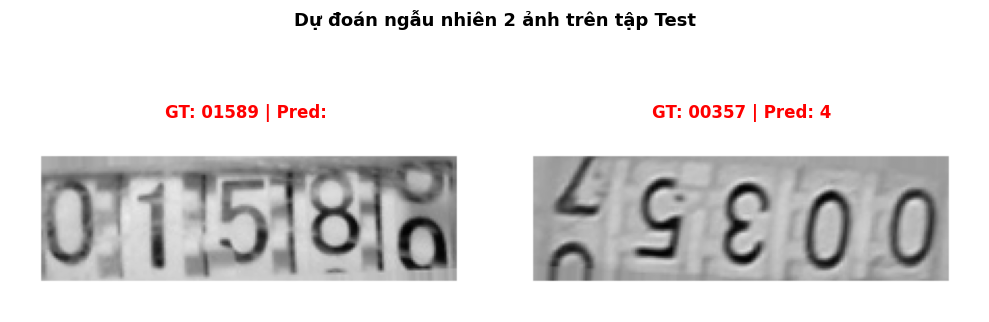

In [ ]:
random.seed(42)
indices = random.sample(range(len(test_df)), 2)
sample_results = []

for idx in indices:
    row = test_df.iloc[idx]
    img_name = row['filename']
    gt = str(row['label']).strip()
    
    img = cv2.imread(str(TEST_IMAGES / img_name))
    processed_img = preprocessor.preprocess(img)
    raw_pred = pytesseract.image_to_string(processed_img, lang=tess_lang, config=tess_config)
    pred = ''.join([c for c in raw_pred if c.isdigit()])
    sample_results.append((processed_img, gt, pred))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for idx, (img_vis, gt, pred) in enumerate(sample_results):
    axes[idx].imshow(img_vis, cmap='gray')
    color = 'green' if gt == pred else 'red'
    axes[idx].set_title(f'GT: {gt} | Pred: {pred}', color=color, fontsize=12, fontweight='bold')
    axes[idx].axis('off')
plt.suptitle('Dự đoán ngẫu nhiên 2 ảnh trên tập Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()